# 2. Exploratory Data Analysis (EDA)
This notebook explores distributions, cloud resource consumption behaviors, and feature correlations with total infrastructure cost (`total_cost_inr`).


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="mako")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_PATH = os.path.join("..", "data", "cleaned_cloud_billings.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset Loaded. Shape:", df.shape)
df.describe().T


Dataset Loaded. Shape: (124275, 15)


,count,mean,std,min,25%,50%,75%,max
resource_id,124275.0,501.254379,290.256688,1.000000,251.00000,500.0000,755.00000,1.000000e+03
usage_quantity,124275.0,281.140043,292.984368,1.000000,54.43040,129.0000,477.00000,1.699000e+03
cpu_utilization,124275.0,50.044533,28.917505,0.000000,24.86500,50.1200,75.14000,1.000000e+02
memory_utilization,124275.0,50.009794,28.932216,0.000000,24.96000,49.9300,75.15000,1.000000e+02
cost_per_quantity,124275.0,5.056600,2.862321,0.100100,2.56845,5.0542,7.54530,9.999900e+00
unrounded_cost,124275.0,1419.920349,1881.109525,0.138200,190.15255,557.2420,1915.78205,1.399077e+04
rounded_cost,124275.0,1419.920595,1881.108874,0.000000,190.00000,557.0000,1916.00000,1.399100e+04
total_cost_inr,124275.0,117853.409423,156132.036502,0.000000,15770.00000,46231.0000,159028.00000,1.161253e+06
network_inbound_GB,124275.0,499.957730,288.970052,1.001984,249.07500,499.7240,749.90200,9.999830e+02
network_outbound_GB,124275.0,500.458197,288.970663,1.183427,249.57700,500.1940,750.38750,1.000860e+03


In [2]:
df.head()

,resource_id,service_name,usage_quantity,usage_unit,region_zone,cpu_utilization,memory_utilization,usage_start_time,usage_end_time,cost_per_quantity,unrounded_cost,rounded_cost,total_cost_inr,network_inbound_GB,network_outbound_GB
0,433,Artifact Registry,78.4386,GB,asia-east1,93.44,82.65,2022-01-01 00:00:00,2022-01-04 13:00:00,1.9891,156.0222,156,12948,444.26800,444.679000
1,155,Dialogflow,192.0000,Requests,asia-south1,59.39,75.17,2022-01-01 00:00:00,2022-01-09 01:00:00,8.8297,1695.3024,1695,140685,894.30700,894.806000
2,934,Cloud Pub/Sub,313.0000,Requests,us-west1,71.72,83.31,2022-01-01 00:00:00,2022-01-06 22:00:00,7.4046,2317.6398,2318,192394,196.74700,197.532000
3,511,Cloud Armor,262.0000,Requests,us-central1,86.48,27.19,2022-01-01 00:00:00,2022-01-05 07:00:00,9.1351,2393.3962,2393,198619,87.12617,87.921118
4,666,Cloud Tasks,232.0000,Requests,asia-east1,99.56,51.72,2022-01-01 00:00:00,2022-01-03 15:00:00,4.7032,1091.1424,1091,90553,421.94700,422.011000


In [3]:
df.drop(columns=['network_outbound_GB'],inplace = True)

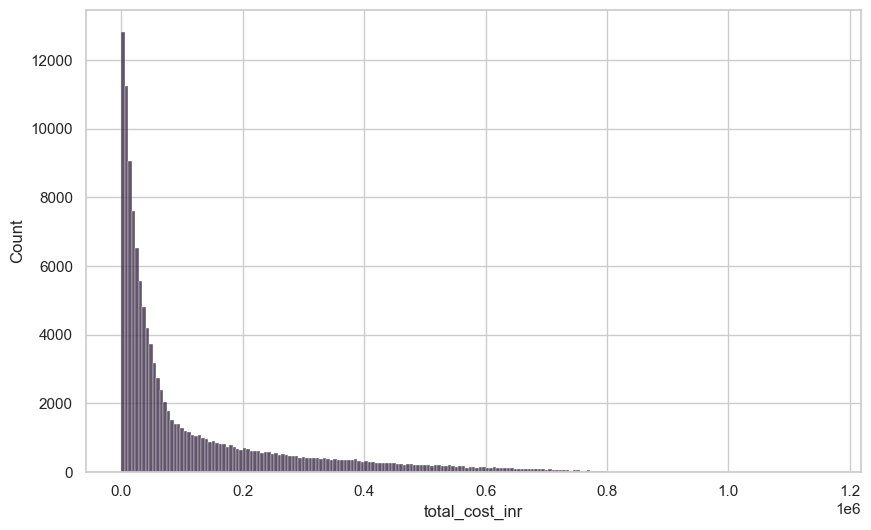

In [4]:
sns.histplot(data = df , x = 'total_cost_inr')
plt.show()

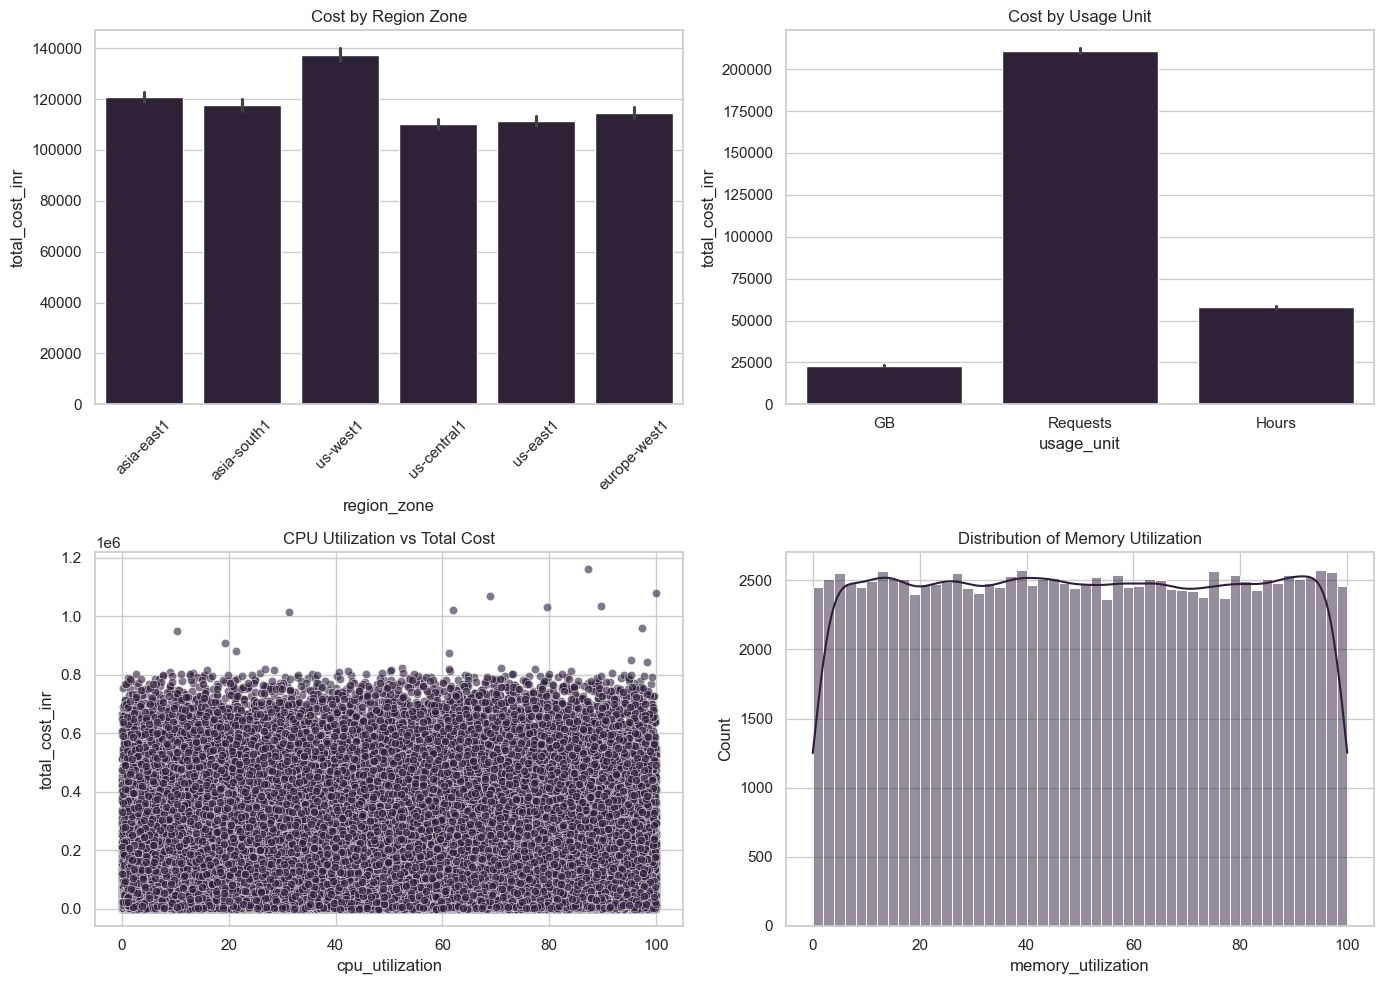

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Increased height (10) so the two rows don't squash each other
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Row 1: Categorical columns (Bar plots work great here)
sns.barplot(data=df, x='region_zone', y='total_cost_inr', ax=axes[0,0])
axes[0,0].set_title('Cost by Region Zone')
axes[0,0].tick_params(axis='x', rotation=45) # Rotates labels if they are long

sns.barplot(data=df, x='usage_unit', y='total_cost_inr', ax=axes[0,1])
axes[0,1].set_title('Cost by Usage Unit')

# Row 2: Continuous columns (Changed to Scatter/Hist to handle numeric data properly)
# Option A: Scatterplot to see how utilization drives cost
sns.scatterplot(data=df, x='cpu_utilization', y='total_cost_inr', ax=axes[1,0], alpha=0.6)
axes[1,0].set_title('CPU Utilization vs Total Cost')

# Option B: Histplot if you just want to see the distribution of memory usage
sns.histplot(data=df, x='memory_utilization', ax=axes[1,1], kde=True)
axes[1,1].set_title('Distribution of Memory Utilization')

# Clean up layout so nothing overlaps
plt.tight_layout()
plt.show()


In [6]:
df['usage_start_time'] = pd.to_datetime(df['usage_start_time'])
df['usage_end_time'] = pd.to_datetime(df['usage_end_time'])
df['usage_duration_hours'] = (df['usage_end_time'] - df['usage_start_time']).dt.total_seconds() / 3600

In [7]:
df.columns

Index(['resource_id', 'service_name', 'usage_quantity', 'usage_unit',
       'region_zone', 'cpu_utilization', 'memory_utilization',
       'usage_start_time', 'usage_end_time', 'cost_per_quantity',
       'unrounded_cost', 'rounded_cost', 'total_cost_inr',
       'network_inbound_GB', 'usage_duration_hours'],
      dtype='object')

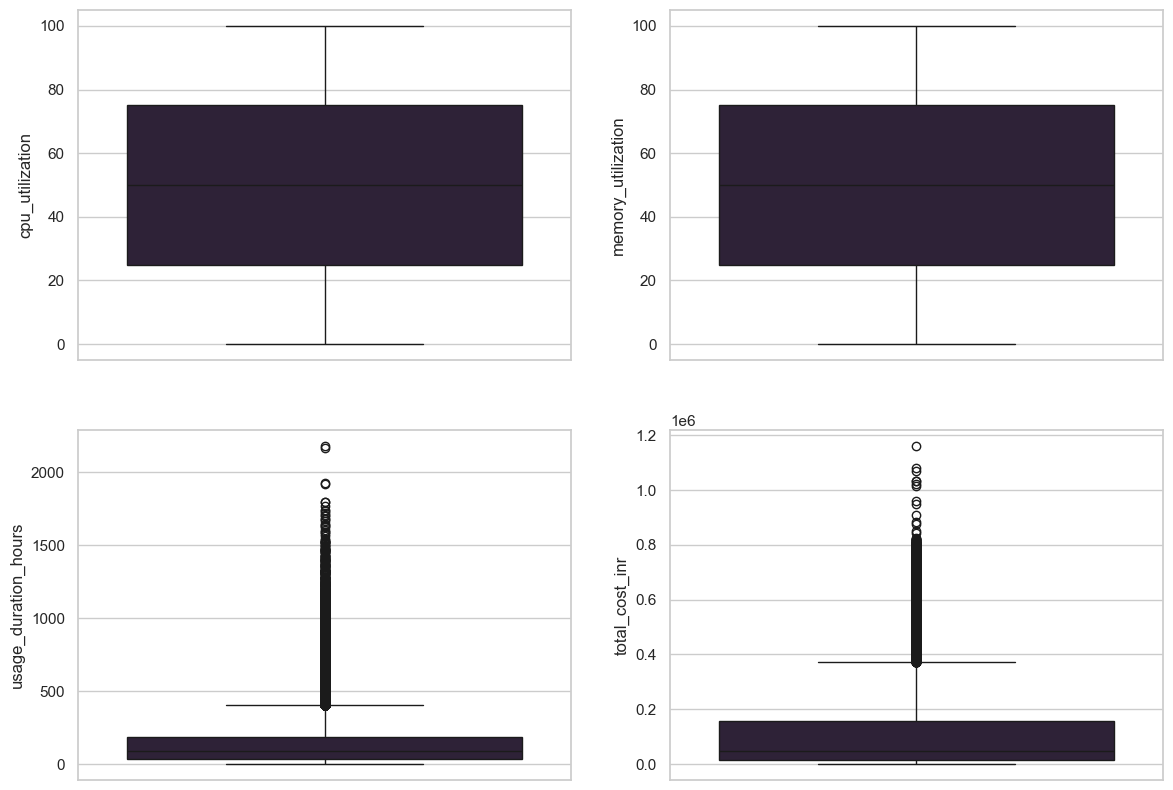

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.boxplot(data = df , y = 'cpu_utilization' , ax= axes[0,0])
sns.boxplot(data = df , y = 'memory_utilization' , ax= axes[0,1])
sns.boxplot(data = df , y = 'usage_duration_hours' , ax= axes[1,0])
sns.boxplot(data = df , y = 'total_cost_inr' , ax= axes[1,1])
plt.show()

In [9]:
df['usage_month'] = df['usage_start_time'].dt.month
df['usage_day_of_week'] = df['usage_start_time'].dt.dayofweek
df['usage_hour'] = df['usage_start_time'].dt.hour
df['is_weekend'] = df['usage_day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

['resource_id', 'usage_quantity', 'cpu_utilization', 'memory_utilization', 'cost_per_quantity', 'unrounded_cost', 'rounded_cost', 'total_cost_inr', 'network_inbound_GB', 'usage_duration_hours', 'usage_month', 'usage_day_of_week', 'usage_hour', 'is_weekend']


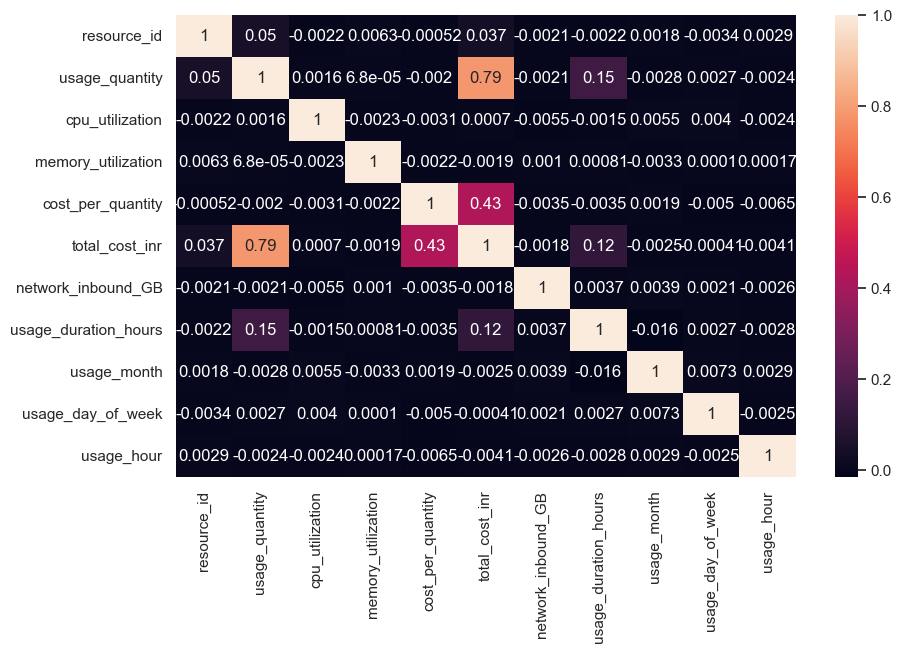

In [10]:
col = df.select_dtypes('number').columns.to_list()
print(col)
corr = df[['resource_id','usage_quantity','cpu_utilization','memory_utilization','cost_per_quantity','total_cost_inr','network_inbound_GB','usage_duration_hours','usage_month','usage_day_of_week','usage_hour']].corr()

sns.heatmap(corr , annot = True)
plt.show()

In [11]:
df.to_csv('../data/featured_cloud_billings.csv', index=False)